titre du projet 
nom des peersonne du groupe 

In [2]:
import pandas as pd
import numpy as np 
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.metrics import matthews_corrcoef
from sklearn.pipeline import make_pipeline
import itertools
import time
import traceback
import csv

# I. visualisation des donnée 
doc seaborn : https://seaborn.pydata.org/index.html

In [5]:
import seaborn as sns 
import matplotlib.pyplot as plt
import math
import pandas as pd 

In [8]:
train = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/train.csv', index_col='id')
train.info()
train

<class 'pandas.DataFrame'>
RangeIndex: 3116945 entries, 0 to 3116944
Data columns (total 21 columns):
 #   Column                Dtype  
---  ------                -----  
 0   class                 str    
 1   cap-diameter          float64
 2   cap-shape             str    
 3   cap-surface           str    
 4   cap-color             str    
 5   does-bruise-or-bleed  str    
 6   gill-attachment       str    
 7   gill-spacing          str    
 8   gill-color            str    
 9   stem-height           float64
 10  stem-width            float64
 11  stem-root             str    
 12  stem-surface          str    
 13  stem-color            str    
 14  veil-type             str    
 15  veil-color            str    
 16  has-ring              str    
 17  ring-type             str    
 18  spore-print-color     str    
 19  habitat               str    
 20  season                str    
dtypes: float64(3), str(18)
memory usage: 499.4 MB


,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,...,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
id,,,,,,,,,,,,,,,,,,,,,
0,e,8.80,f,s,u,f,a,c,w,4.51,...,NaN,NaN,w,NaN,NaN,f,f,NaN,d,a
1,p,4.51,x,h,o,f,a,c,n,4.79,...,NaN,y,o,NaN,NaN,t,z,NaN,d,w
2,e,6.94,f,s,b,f,x,c,w,6.85,...,NaN,s,n,NaN,NaN,f,f,NaN,l,w
3,e,3.88,f,y,g,f,s,NaN,g,4.16,...,NaN,NaN,w,NaN,NaN,f,f,NaN,d,u
4,e,5.85,x,l,w,f,d,NaN,w,3.37,...,NaN,NaN,w,NaN,NaN,f,f,NaN,g,a
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3116940,e,9.29,f,NaN,n,t,NaN,NaN,w,12.14,...,b,NaN,w,u,w,t,g,NaN,d,u
3116941,e,10.88,s,NaN,w,t,d,c,p,6.65,...,NaN,NaN,w,NaN,NaN,f,f,NaN,d,u
3116942,p,7.82,x,e,e,f,a,NaN,w,9.51,...,NaN,NaN,y,NaN,w,t,z,NaN,d,a


## I.1 Visualisation de la distribution 
### I.1.1 Les données quantitatives

Dans cette partie, seules les variables `cap-diameter`, `stem-height` et `stem-width` seront traitées, car ce sont les seules variables quantitatives du jeu de données. Nous utilisons la fonction `displot` de Seaborn pour visualiser la répartition de leurs valeurs.

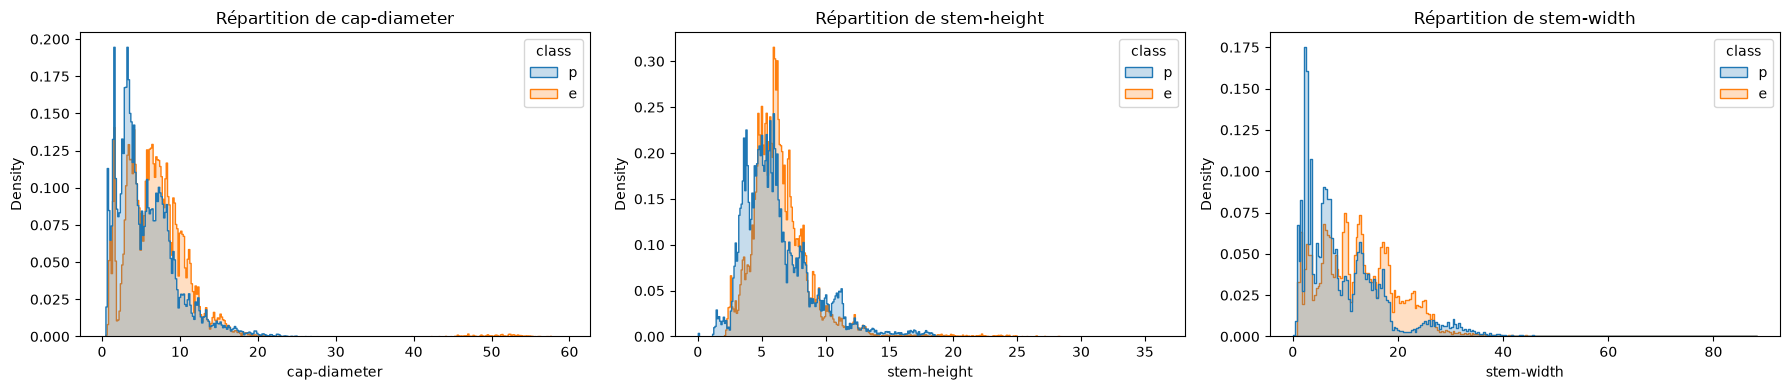

,min,max,mean,median,std,etendue,IQR,cv
cap-diameter,0.03,80.67,6.31,5.75,4.66,80.64,4.92,0.74
stem-height,0.00,88.72,6.35,5.88,2.70,88.72,2.74,0.43
stem-width,0.00,102.90,11.15,9.65,8.10,102.90,10.66,0.73


In [25]:
quantitatives = test.select_dtypes(include="number").columns.tolist()
qualitatives = test.select_dtypes(exclude="number").columns.tolist()
fig, axes = plt.subplots(1, len(quantitatives), figsize=(18, 4))

for ax, col in zip(axes, quantitatives):
    sns.histplot(data=df, x=col, hue="class",
                 stat="density", common_norm=False,
                 element="step", ax=ax)
    ax.set_title(f"Répartition de {col}")

plt.tight_layout()
plt.show()
resume = train[quantitatives].agg(["min", "max", "mean", "median", "std"]).T
resume["etendue"] = resume["max"] - resume["min"]
resume["IQR"] = (train[quantitatives].quantile(0.75)
                 - train[quantitatives].quantile(0.25))
resume["cv"] = resume["std"] / resume["mean"]
resume.round(2)

Les trois variables quantitatives présentent une distribution asymétrique à droite (moyenne supérieure à la médiane). Les étendues sont très larges (jusqu’à 103 pour `stem-width`) par rapport à la dispersion centrale (IQR de 2,7 à 10,7), ce qui révèle des valeurs extrêmes qui seront examinées et éventuellement plafonnées avant la modélisation. Un traitement de ces variables (plafonnement des valeurs extrêmes, transformation logarithmique) pourra être appliqué selon le modèle retenu : les modèles à base d’arbres y sont peu sensibles, contrairement aux modèles linéaires.

### I.1.1 Les données quantitatif  

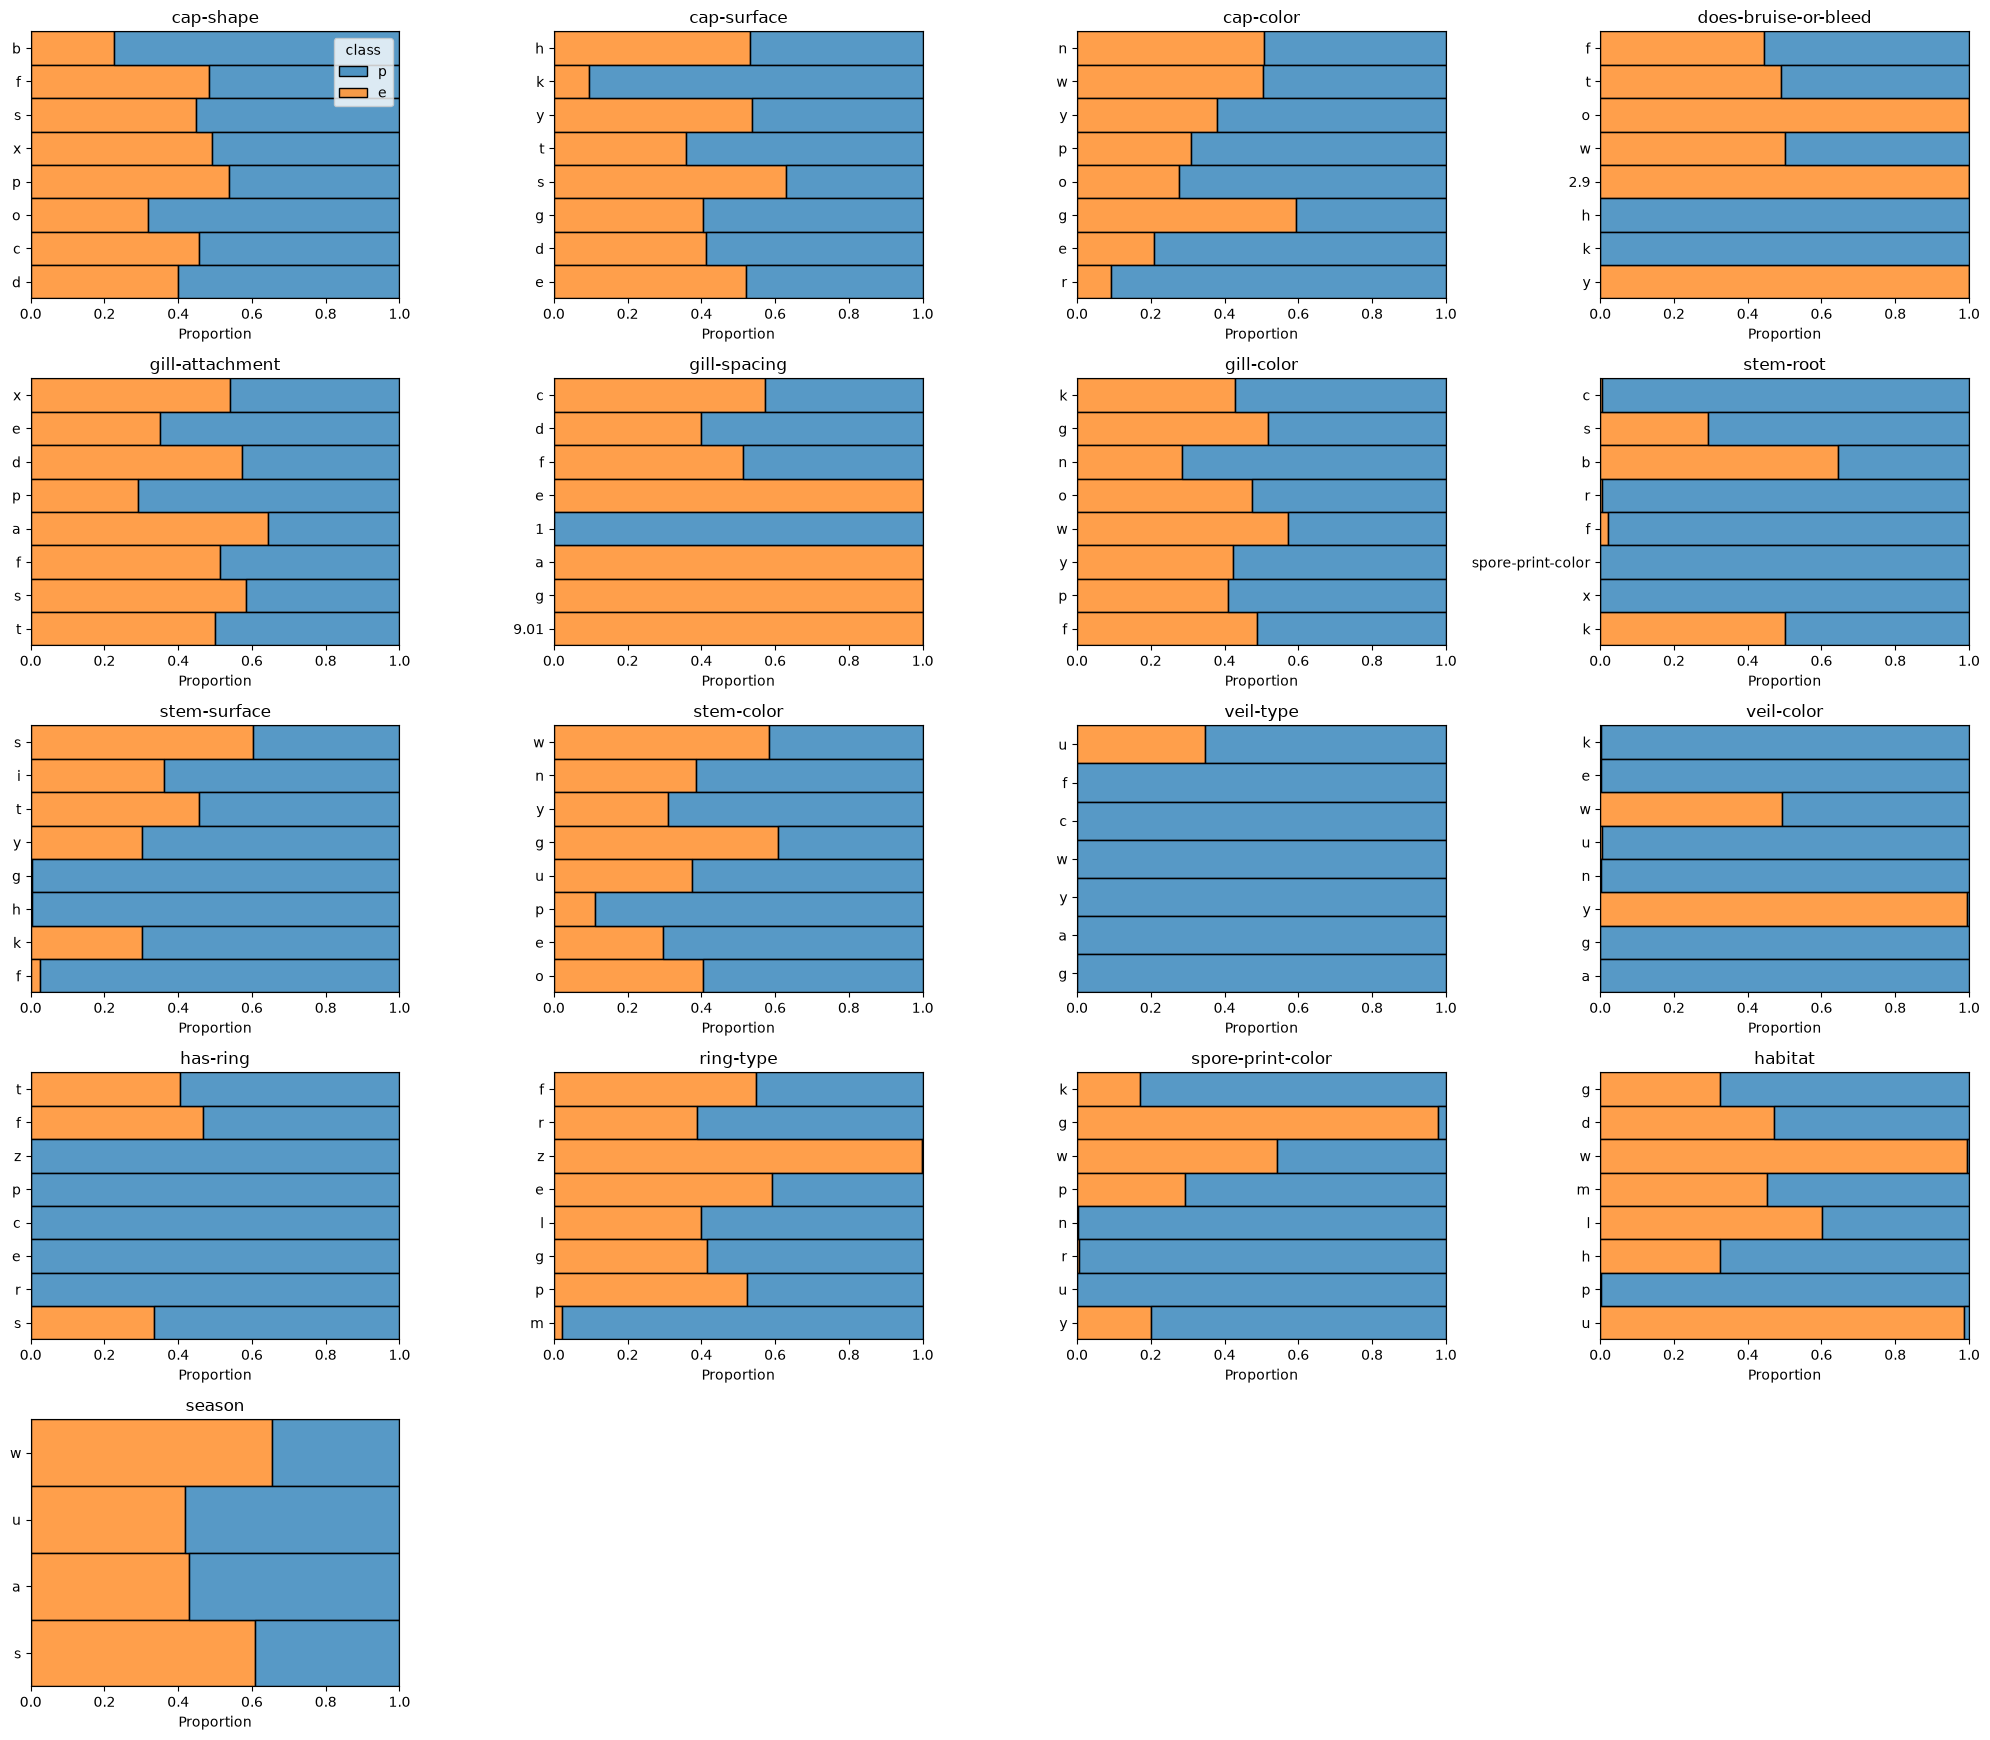

,nb_modalites,modalite_dominante,part_dominante_%,nb_modalites_rares(<1%),manquants_%
veil-type,22,u,99.95,21,94.88
spore-print-color,32,k,40.15,25,91.43
stem-root,38,b,46.07,34,88.45
veil-color,24,w,74.22,18,87.94
stem-surface,60,s,28.84,53,63.55
gill-spacing,48,c,71.62,45,40.37
cap-surface,83,t,18.84,72,21.53
gill-attachment,78,a,24.91,71,16.81
ring-type,40,f,82.90,33,4.13
cap-shape,74,x,46.07,67,0.00


In [22]:
ncols = 4
nrows = math.ceil(len(qualitatives) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
axes = axes.ravel()

for ax, col in zip(axes, qualitatives):
    top = df[col].value_counts().nlargest(8).index
    sub = df[df[col].isin(top)]
    sns.histplot(data=sub, y=col, hue="class", multiple="fill",
                 stat="proportion", ax=ax, legend=(ax is axes[0]))
    ax.set_title(col)
    ax.set_ylabel("")

for ax in axes[len(qualitatives):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()
resume_cat = pd.DataFrame({
    "nb_modalites": train[qualitatives].nunique(),
    "modalite_dominante": train[qualitatives].mode().iloc[0],
    "part_dominante_%": [train[c].value_counts(normalize=True).iloc[0] * 100
                         for c in qualitatives],
    "nb_modalites_rares(<1%)": [(train[c].value_counts(normalize=True) < 0.01).sum()
                                for c in qualitatives],
    "manquants_%": train[qualitatives].isna().mean() * 100,
})
resume_cat.round(2).sort_values("manquants_%", ascending=False)

Quatre variables qualitatives (`veil-type`, `spore-print-color`, `stem-root`, `veil-color`) sont écartées dans un premier temps, car elles sont presque entièrement manquantes (88 % à 95 %), `veil-type` étant en outre quasi constante. Les modalités rares y seront regroupées et les valeurs manquantes traitées explicitement. Cette sélection sera confirmée en comparant les performances du modèle avec et sans les variables écartées.

### Conclusion
À la suite de cette étape, les champs suivants seront conservés pour la modélisation, avec un possible traitement selon le modèle choisi :
    
* **Variables quantitatives :** `cap-diameter`, `stem-height`, `stem-width`
      * **État :** Complètes, mais leur distribution est asymétrique à droite et comporte des valeurs extrêmes.
      * **Traitement envisagé :** Un plafonnement ou une transformation logarithmique pourra être appliqué selon le modèle retenu (peu utile pour les modèles à base d’arbres, recommandé pour les modèles linéaires).
    
    * **Variables qualitatives :** `cap-shape`, `cap-surface`, `cap-color`, `does-bruise-or-bleed`, `gill-attachment`, `gill-spacing`, `gill-color`, `stem-surface`, `stem-color`, `has-ring`, `ring-type`, `habitat`, `season`
      * **Traitement envisagé :** Les modalités rares (moins de 1 %) seront regroupées dans une catégorie « autre », et les valeurs manquantes seront traitées explicitement dans une catégorie « manquant ».
    
    
    * **Variables écartées dans un premier temps :** `veil-type`, `spore-print-color`, `stem-root`, `veil-color`
    
      
      **Motif :**  Elles sont presque entièrement manquantes (88 % à 95 %), `veil-type` étant de plus quasi constante (99,95 % de `u`).

## I.2 Visualisation de la correspondance des different jeux de tests

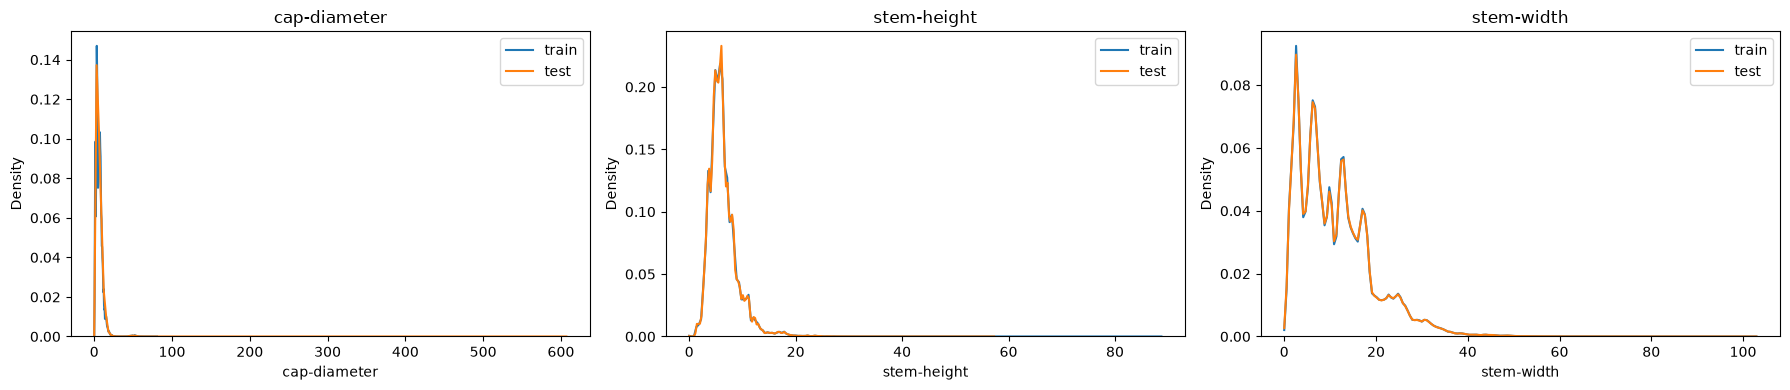

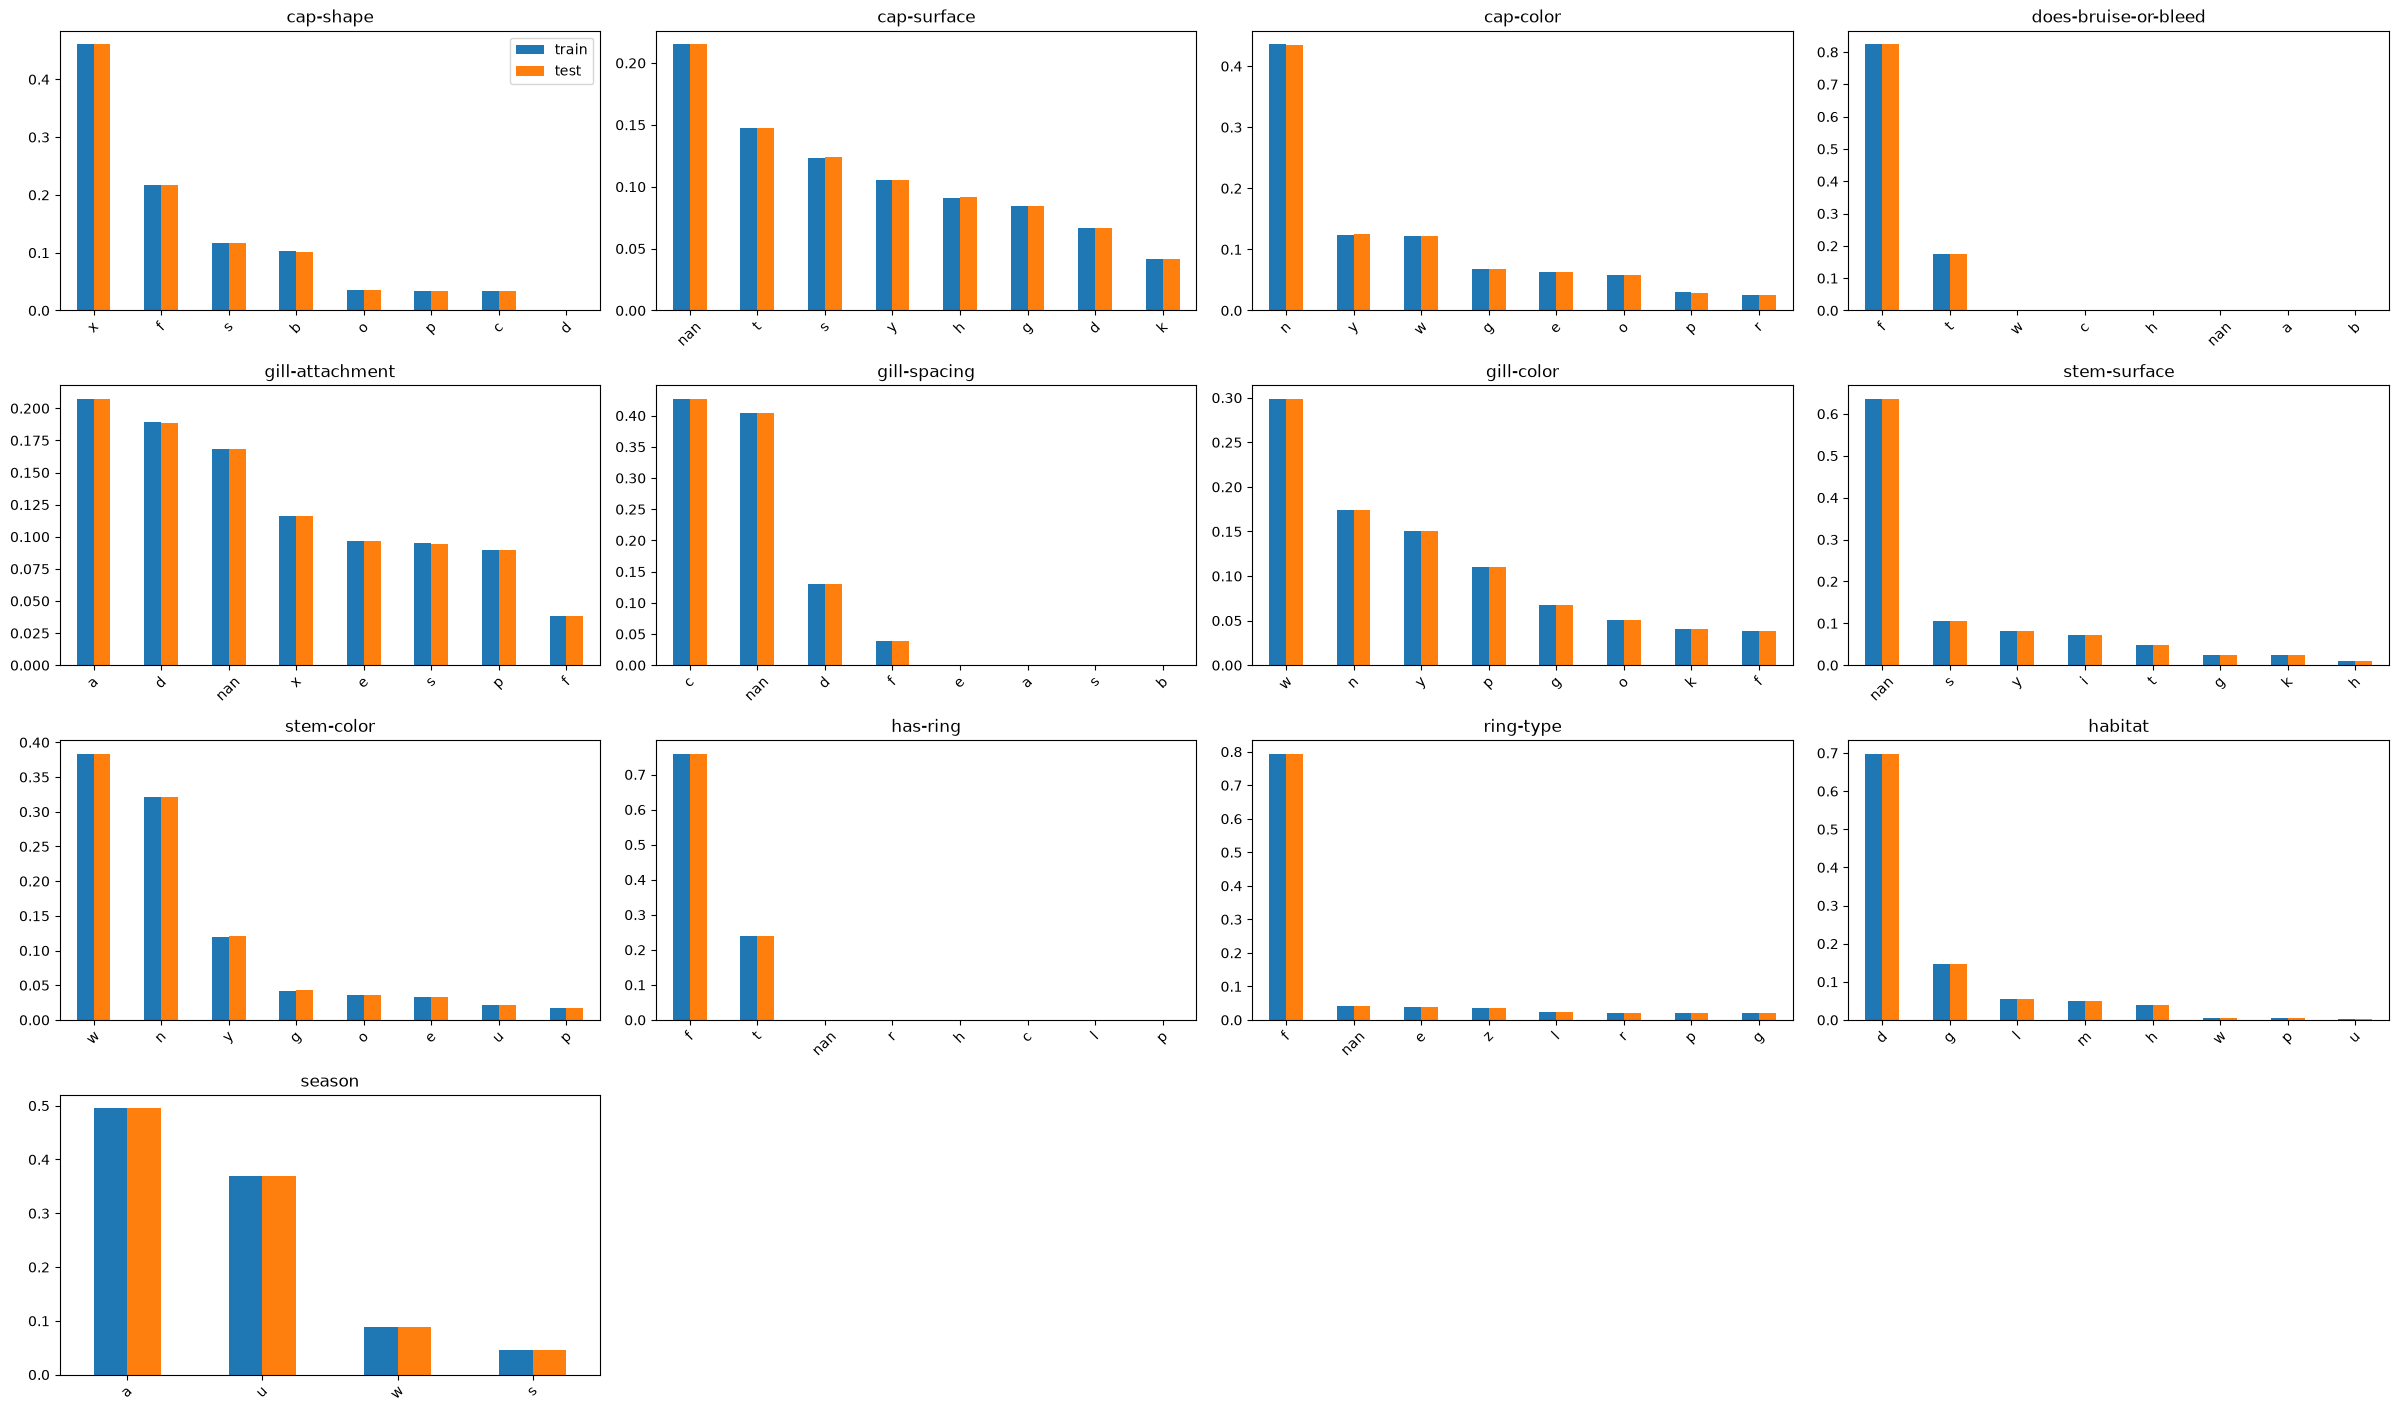

In [26]:
test = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/test.csv', index_col='id')
fig, axes = plt.subplots(1, len(quantitatives), figsize=(18, 4))
for ax, col in zip(axes, quantitatives):
    sns.kdeplot(data=train, x=col, label="train", cut=0, common_norm=False, ax=ax)
    sns.kdeplot(data=test,  x=col, label="test",  cut=0, common_norm=False, ax=ax)
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

ncols = 4
nrows = math.ceil(len(qualitatives) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.5 * nrows))
axes = axes.ravel()
a_ecarter = ["veil-type", "spore-print-color", "stem-root", "veil-color"]

qualitatives = [c for c in qualitatives if c not in a_ecarter]
for ax, col in zip(axes, qualitatives):
    comp = pd.DataFrame({
        "train": train[col].value_counts(normalize=True, dropna=False),
        "test":  test[col].value_counts(normalize=True, dropna=False),
    }).fillna(0)
    comp.nlargest(8, "train").plot(kind="bar", ax=ax, legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

for ax in axes[len(qualitatives):]:
    ax.set_visible(False)

axes[0].legend(["train", "test"])
plt.tight_layout()
plt.show()

Grâce aux différents graphiques générés, on remarque que le jeu d'entraînement (train) présente une bonne correspondance avec le jeu de test (test). Cette cohérence confirme que nos données sont saines et prêtes pour la suite du projet.

# II. Netoyage des donnée 
nous avons fait le chois d'effecteur une fonction qui permet de trier les valeur en faisant varier le seul et la methode nous permet

In [3]:
def valeur_manquante(train, a_ecarter, mods, test=None):
    train = train.drop(columns=[c for c in a_ecarter if c in train.columns]).copy()
    if test is not None:
        test = test.drop(columns=[c for c in a_ecarter if c in test.columns]).copy()

    num_cols = train.select_dtypes(include="number").columns.tolist()
    cat_cols = train.select_dtypes(exclude="number").columns.drop("class", errors="ignore").tolist()

    if mods == "SI":      # passer au log 
        imp_num = SimpleImputer(strategy="median")
        imp_cat = SimpleImputer(strategy="constant", fill_value="manquant")

    elif mods == "M":     # médiane (num) + mode (cat)
        imp_num = SimpleImputer(strategy="median")
        imp_cat = SimpleImputer(strategy="most_frequent")

    elif mods == "KNN":   # KNN (num) + mode (cat) : lent, à tester sur échantillon
        imp_num = KNNImputer(n_neighbors=20)
        imp_cat = SimpleImputer(strategy="most_frequent")

    elif mods == "IMP":   # itératif (num) + mode (cat) : lent
        imp_num = IterativeImputer(estimator=HistGradientBoostingRegressor(),
                                   max_iter=5, random_state=0)
        imp_cat = SimpleImputer(strategy="most_frequent")

    else:                 # aucune imputation
        return (train, test) if test is not None else train

    # ajustement sur le TRAIN uniquement
    train[num_cols] = imp_num.fit_transform(train[num_cols])
    train[cat_cols] = imp_cat.fit_transform(train[cat_cols])

    if test is not None:
        test[num_cols] = imp_num.transform(test[num_cols])
        test[cat_cols] = imp_cat.transform(test[cat_cols])
        return train, test
    return train


# Création du modele predictive 

In [4]:
def entrainement_des_modele(train, test, mods="R", type_mod="HistGradientBoostingClassifier"):
    a_ecarter = ["veil-type", "spore-print-color", "stem-root", "veil-color"]
    entrai, test = valeur_manquante(train, a_ecarter, mods, test)
    # titre de la partie
    y = entrai["class"]
    X = entrai.drop(columns=["class"]).copy()
    cat_cols = X.select_dtypes(include=["object", "str"]).columns    
    for col in cat_cols:  # transformer un v
        X[col] = X[col].astype("category")

    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # encodeur pour les modèles qui n'acceptent pas le texte / les catégories
    encodeur = ColumnTransformer(
        [("cat", OrdinalEncoder(handle_unknown="use_encoded_value",
                                unknown_value=-1,
                                encoded_missing_value=-1), list(cat_cols))],
        remainder="passthrough"
    )

    if type_mod == "HistGradientBoostingClassifier":
        model = HistGradientBoostingClassifier(
            categorical_features="from_dtype",
            max_iter=100,
            learning_rate=0.1,
            random_state=42
        )
    elif type_mod == "IterativeImputer":
        # IterativeImputer n'a pas de predict : on l'insère dans un pipeline
        # (encodage -> imputation -> classifieur) pour qu'il soit utilisable
        model = make_pipeline(
            encodeur,
            IterativeImputer(
                estimator=RandomForestRegressor(n_estimators=25, max_depth=12, n_jobs=-1, random_state=0),
                max_iter=5,
                initial_strategy= 'most_frequent',
                random_state=0,
            ),
            HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42)
        )
    elif type_mod == "RandomForestClassifier":
        model = make_pipeline(
            encodeur,
            RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=42)
        )
    elif type_mod == "GradientBoostingClassifier":
        model = make_pipeline(
            encodeur,
            GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
        )
    else:
        print("le modele que vous souhaiter tester n'existe pas, le modele par defaut est HistGradientBoostingClassifier")
        model = HistGradientBoostingClassifier(
            categorical_features="from_dtype",
            max_iter=100,
            learning_rate=0.1,
            random_state=42
        )

    model.fit(X_train, y_train)
    #X_test = val_manquant(test, seuil, ops)
    X_test = test[X.columns]
    for col in cat_cols:
        X_test[col] = X_test[col].where(X_test[col].isin(X[col].cat.categories))
        X_test[col] = pd.Categorical(X_test[col], categories=X[col].cat.categories)

    predictions = model.predict(X_test)
    y_pred = model.predict(X_val)
    mcc = matthews_corrcoef(y_val, y_pred)
    print(f"MCC sur validation : {mcc:.4f}")

    return model, predictions, mcc


# Phase de test 
Nous effectuons la phase de test sur un échantillon incomplet. Nous avons identifié 46 combinaisons possibles, mais les exécuter toutes sur l'ensemble des données demanderait trop de ressources. De ce fait, nous avons choisi un échantillon représentatif d'environ 10 000 lignes.

In [66]:
def copi_fichier(n, train,test):
    train_copie = []
    test_copie = []
    for i in range(n):
        train_copie.append(train.copy())
        test_copie.append(test.copy())
    return train_copie, test_copie 

In [11]:
imputations = ["SI", "M", "KNN", "IMP"]
types_mod = ["HistGradientBoostingClassifier", "IterativeImputer",
             "RandomForestClassifier", "GradientBoostingClassifier"]

train = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/train.csv', index_col='id')
test = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/test.csv', index_col='id')

train_s = train.head(50000)
test_s = test.head(50000)

taille = len(imputations) * len(types_mod)   # 16
i = 1
resul = []

for val_manq in imputations:
    for type_mo in types_mod:
        print(f"[{i}/{taille}] ops={val_manq}, type_mod={type_mo}")
        mod, preds, mcc = entrainement_des_modele(train_s, test_s,mods =val_manq, type_mod=type_mo)
        resul.append((val_manq, type_mo, mcc))
        i += 1

df_resul = pd.DataFrame(resul, columns=["imputation valeur manquante", "type de modele utiliser", "mcc"])
df_resul = df_resul.sort_values("mcc", ascending=False).reset_index(drop=True)
print(df_resul)

meilleur = df_resul.iloc[0]
print(f"\nMeilleur MCC : {meilleur['mcc']:.4f} "
      f"({meilleur['type_mod']}, ops={meilleur['ops']})")

[1/16] ops=SI, type_mod=HistGradientBoostingClassifier
MCC sur validation : 0.9784
[2/16] ops=SI, type_mod=IterativeImputer
MCC sur validation : 0.9720
[3/16] ops=SI, type_mod=RandomForestClassifier
MCC sur validation : 0.9792
[4/16] ops=SI, type_mod=GradientBoostingClassifier
MCC sur validation : 0.8136
[5/16] ops=M, type_mod=HistGradientBoostingClassifier
MCC sur validation : 0.9742
[6/16] ops=M, type_mod=IterativeImputer
MCC sur validation : 0.9701
[7/16] ops=M, type_mod=RandomForestClassifier
MCC sur validation : 0.9762
[8/16] ops=M, type_mod=GradientBoostingClassifier
MCC sur validation : 0.8449
[9/16] ops=KNN, type_mod=HistGradientBoostingClassifier
MCC sur validation : 0.9742
[10/16] ops=KNN, type_mod=IterativeImputer
MCC sur validation : 0.9701
[11/16] ops=KNN, type_mod=RandomForestClassifier
MCC sur validation : 0.9762
[12/16] ops=KNN, type_mod=GradientBoostingClassifier
MCC sur validation : 0.8449
[13/16] ops=IMP, type_mod=HistGradientBoostingClassifier
MCC sur validation : 0

KeyError: 'type_mod'

# Choix du modele 
Grâce à la phase de test, nous avons choisi le modèle suivant : RandomForestClassifier. Maintenant, nous allons faire varier les différents arguments de ce modèle.

In [8]:
train = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/train.csv', index_col='id')
test = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/test.csv', index_col='id')

train_s = train
test_s = test
mod, preds, mcc = entrainement_des_modele(train_s, test_s,mods ="SI", type_mod="RandomForestClassifier")
print(mcc)
print(preds)

MCC sur validation : 0.9837
0.9837140489201314
['e' 'p' 'p' ... 'p' 'e' 'e']


In [9]:
def creer_csv(id_test, pred_test, nom_fichier="submission.csv"):
    with open(nom_fichier, mode="w", newline="", encoding="utf-8") as fichier:
        writer = csv.writer(fichier)
        writer.writerow(["id", "class"])        # en-tête
        writer.writerows(zip(id_test, pred_test))  # une ligne par (id, prédiction)

creer_csv(test.index, preds)

In [10]:
train = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/train.csv', index_col='id')
test = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/test.csv', index_col='id')

train_s = train
test_s = test
mod, preds, mcc = entrainement_des_modele(train_s, test_s,mods ="SI", type_mod="HistGradientBoostingClassifier")
print(mcc)
print(preds)

MCC sur validation : 0.9803
0.980297055292047
['e' 'p' 'p' ... 'p' 'e' 'e']


| Modèles | Variables qualitatives | Variables quantitatives |
| :--- | :--- | :--- |
| **SVC**<br>**LinearSVC**<br>**LogisticRegression**<br>**LogisticRegressionCV** | 1. Imputation par la catégorie `"manquante"`<br>2. Encodage avec `OneHotEncoder` (seuil à 1 %)| 1. Imputation par la médiane<br>2. Transformation logarithmique (`log`)<br>3. Standardisation (centrage-réduction)|
| **KNeighborsClassifier** | 1. Imputation par la catégorie `"manquante"`<br>2. Encodage avec `OneHotEncoder` (seuil à 5 %)| 1. Imputation par la médiane<br>2. Transformation logarithmique (`log`)<br>3. Standardisation (centrage-réduction)|
| **GradientBoostingClassifier**<br>**RandomForestClassifier**<br>**DecisionTreeClassifier** | 1. Imputation par la catégorie `"manquante"`<br>2. Encodage avec `OrdinalEncoder`| Imputation par la médiane|
| **HistGradientBoostingClassifier** | Encodage avec `OrdinalEncoder` *(gestion native des valeurs manquantes)*| Aucun prétraitement *(gestion native des valeurs manquantes)*|